In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [19]:
import huggingface_hub
print("Hugging Face Hub:", huggingface_hub.__version__)

from pathlib import Path

p = Path("/kaggle/working/RAM-W600")
print("RAM-W600 folder exists:", p.exists())

if p.exists():
    for f in list(p.rglob("*"))[:20]:
        print(f)

Hugging Face Hub: 1.29.0
RAM-W600 folder exists: True
/kaggle/working/RAM-W600/.cache
/kaggle/working/RAM-W600/BoneSegmentation
/kaggle/working/RAM-W600/.cache/huggingface
/kaggle/working/RAM-W600/BoneSegmentation/images
/kaggle/working/RAM-W600/.cache/huggingface/download
/kaggle/working/RAM-W600/.cache/huggingface/CACHEDIR.TAG
/kaggle/working/RAM-W600/.cache/huggingface/.gitignore
/kaggle/working/RAM-W600/.cache/huggingface/download/.gitattributes.lock
/kaggle/working/RAM-W600/.cache/huggingface/download/BoneSegmentation
/kaggle/working/RAM-W600/.cache/huggingface/download/BoneSegmentation/images
/kaggle/working/RAM-W600/.cache/huggingface/download/BoneSegmentation/images/0006_0001_R.bmp.lock
/kaggle/working/RAM-W600/.cache/huggingface/download/BoneSegmentation/images/0005_0001_R.bmp.lock
/kaggle/working/RAM-W600/.cache/huggingface/download/BoneSegmentation/images/0002_0001_L.bmp.lock
/kaggle/working/RAM-W600/.cache/huggingface/download/BoneSegmentation/images/0001_0001_R.bmp.lock
/k

In [20]:
from huggingface_hub import HfApi

try:
    api = HfApi()
    datasets = list(
        api.list_datasets(search="RAM-W600", limit=10)
    )

    print("Datasets found:", len(datasets))

    for ds in datasets:
        print(ds.id)

except Exception as e:
    print("Error:", repr(e))

Datasets found: 1
TokyoTechMagicYang/RAM-W600


In [21]:
from huggingface_hub import snapshot_download
from kaggle_secrets import UserSecretsClient
from pathlib import Path

token = UserSecretsClient().get_secret("HF_TOKEN")

download_path = "/kaggle/working/RAM-W600"

snapshot_download(
    repo_id="TokyoTechMagicYang/RAM-W600",
    repo_type="dataset",
    local_dir=download_path,
    token=token
)

# Verify actual image and mask files
root = Path(download_path)

images = list(root.rglob("*.bmp"))
masks = list(root.rglob("*.npy"))

print("BMP images:", len(images))
print("NumPy masks:", len(masks))
print("Sample images:", images[:5])
print("Sample masks:", masks[:5])

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 6842 files:   0%|          | 0/6842 [00:00<?, ?it/s]

BMP images: 6218
NumPy masks: 618
Sample images: [PosixPath('/kaggle/working/RAM-W600/BoneSegmentation/images/EXT_0097_0001_L.bmp'), PosixPath('/kaggle/working/RAM-W600/BoneSegmentation/images/0113_0001_R.bmp'), PosixPath('/kaggle/working/RAM-W600/BoneSegmentation/images/EXT_0014_0001_L.bmp'), PosixPath('/kaggle/working/RAM-W600/BoneSegmentation/images/0129_0002_R.bmp'), PosixPath('/kaggle/working/RAM-W600/BoneSegmentation/images/0090_0001_L.bmp')]
Sample masks: [PosixPath('/kaggle/working/RAM-W600/BoneSegmentation/masks/test/EXT_0018_0001_L.npy'), PosixPath('/kaggle/working/RAM-W600/BoneSegmentation/masks/test/0352_0001_R.npy'), PosixPath('/kaggle/working/RAM-W600/BoneSegmentation/masks/test/0050_0001_R.npy'), PosixPath('/kaggle/working/RAM-W600/BoneSegmentation/masks/test/EXT_0065_0001_L.npy'), PosixPath('/kaggle/working/RAM-W600/BoneSegmentation/masks/test/EXT_0074_0001_R.npy')]


RAM-W600 images: 618
X-ray Rheumatology images: 185


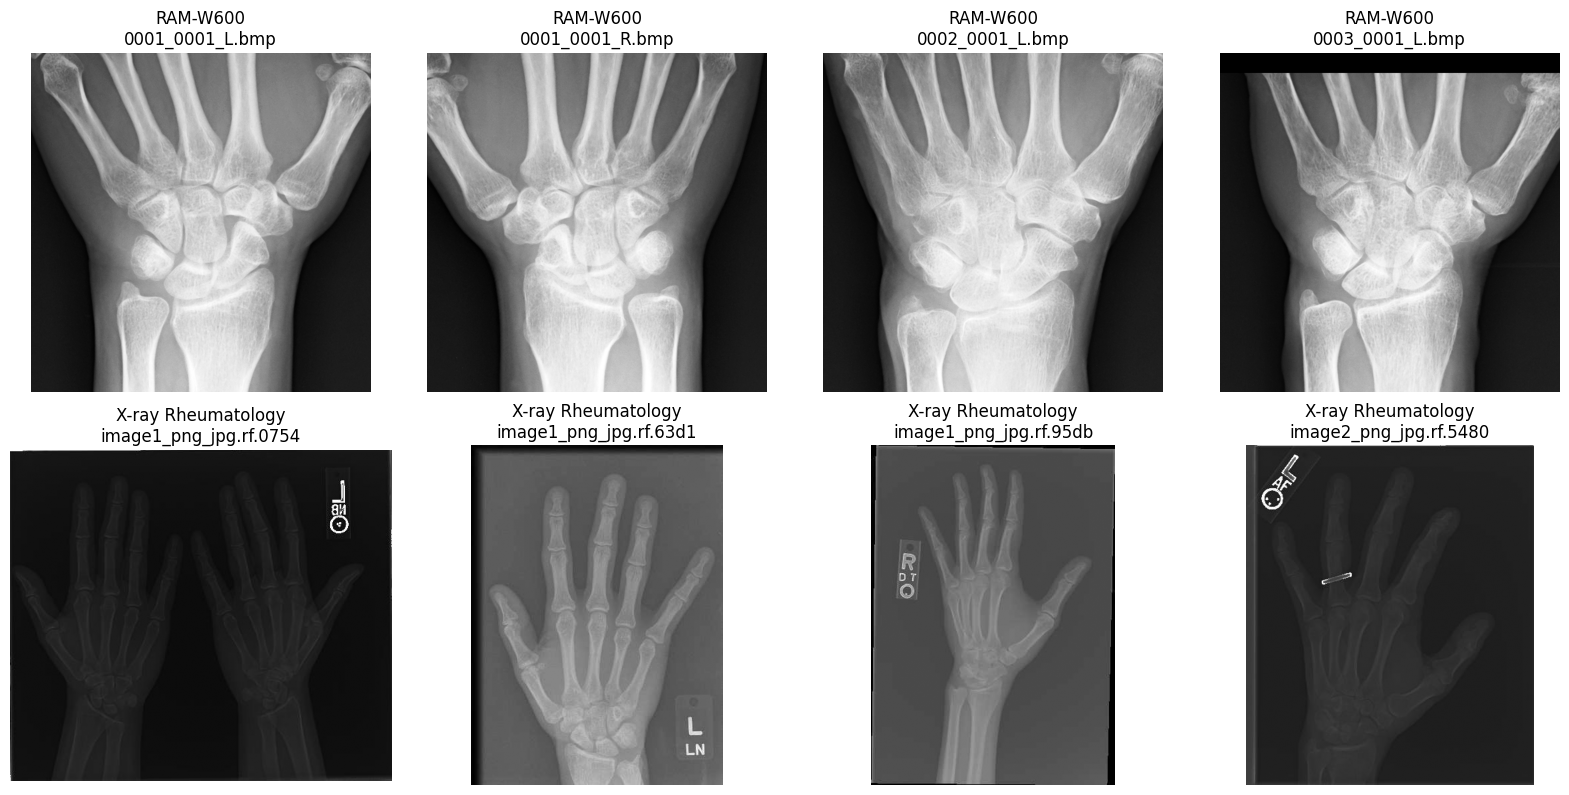

In [32]:

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

# Dataset paths
ram_dir = Path(
    "/kaggle/working/RAM-W600/BoneSegmentation/images"
)

xray_dir = Path(
    "/kaggle/input/datasets/reshmaaelango/"
    "x-ray-rheumatology-computer-vision-model"
)

ram_images = sorted(ram_dir.glob("*.bmp"))

xray_images = sorted([
    p for p in xray_dir.rglob("*")
    if p.is_file()
    and p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]
])

print("RAM-W600 images:", len(ram_images))
print("X-ray Rheumatology images:", len(xray_images))

# Display 4 images from each dataset
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for i, ax in enumerate(axes[0]):
    if i < len(ram_images):
        img = Image.open(ram_images[i]).convert("L")
        ax.imshow(img, cmap="gray")
        ax.set_title(f"RAM-W600\n{ram_images[i].name}")
    ax.axis("off")

for i, ax in enumerate(axes[1]):
    if i < len(xray_images):
        img = Image.open(xray_images[i]).convert("L")
        ax.imshow(img, cmap="gray")
        ax.set_title(f"X-ray Rheumatology\n{xray_images[i].name[:22]}")
    ax.axis("off")

plt.tight_layout()
plt.show()


Total input images: 618


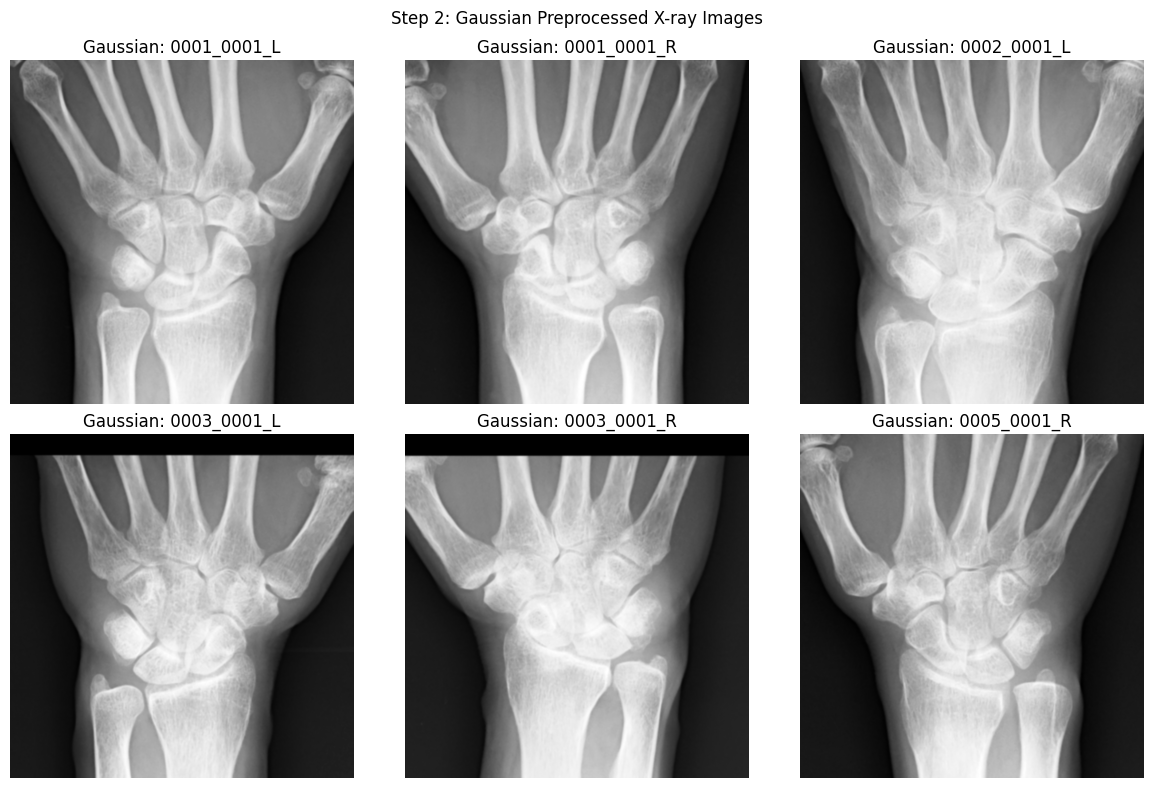

Gaussian preprocessing completed.
Saved output: /kaggle/working/RAM_Gaussian


In [33]:

from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# RAM-W600 dataset
image_dir = Path(
    "/kaggle/working/RAM-W600/BoneSegmentation/images"
)

# Output folder
output_dir = Path("/kaggle/working/RAM_Gaussian")
output_dir.mkdir(parents=True, exist_ok=True)

images = sorted(image_dir.glob("*.bmp"))

print("Total input images:", len(images))

# Process and display first 6 images
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, path in zip(axes.flat, images[:6]):
    image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

    # Gaussian filtering: 5x5 kernel, sigma = 1
    gaussian = cv2.GaussianBlur(
        image, (5, 5), sigmaX=1
    )

    # Min-Max normalization: 0 to 1
    normalized = cv2.normalize(
        gaussian.astype(np.float32),
        None,
        alpha=0,
        beta=1,
        norm_type=cv2.NORM_MINMAX
    )

    # Save processed image
    np.save(
        output_dir / f"{path.stem}.npy",
        normalized.astype(np.float32)
    )

    # Display Gaussian image
    ax.imshow(normalized, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Gaussian: {path.stem}")
    ax.axis("off")

plt.suptitle("Step 2: Gaussian Preprocessed X-ray Images")
plt.tight_layout()
plt.show()

print("Gaussian preprocessing completed.")
print("Saved output:", output_dir)


Preprocessed images: 6
Ground-truth masks: 618
Matching pairs: 6
Sample: 0001_0001_L
Image shape: (600, 600)
Mask shape: (14, 600, 600)


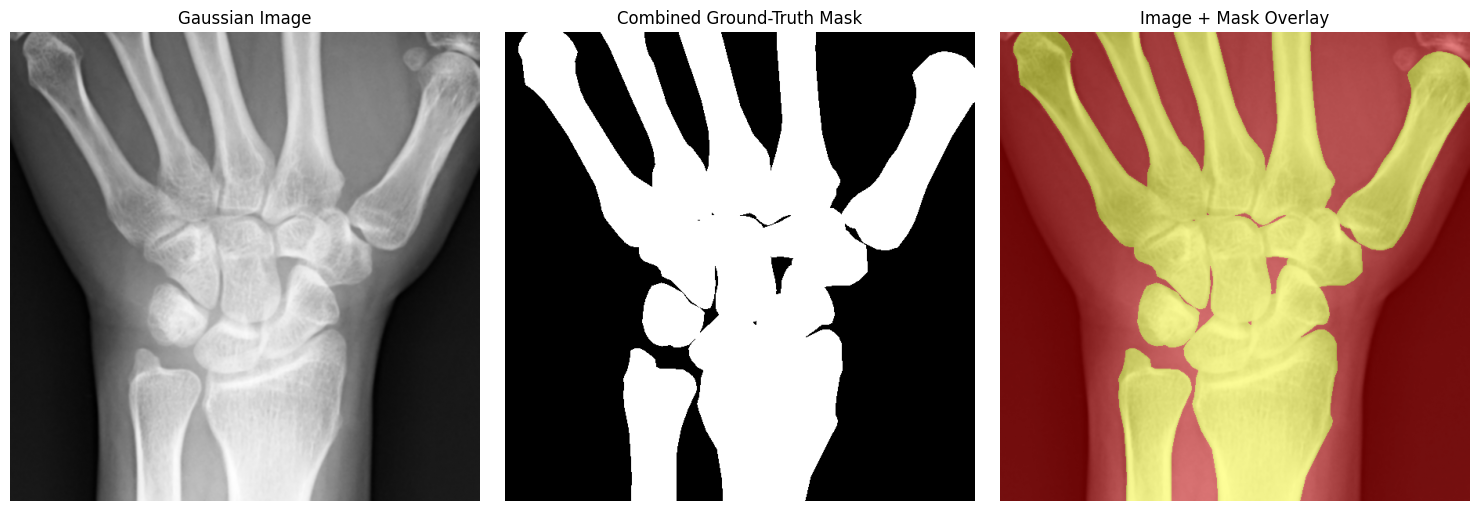

In [36]:

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

image_dir = Path("/kaggle/working/RAM_Gaussian")
mask_dir = Path("/kaggle/working/RAM-W600/BoneSegmentation/masks")

image_files = sorted(image_dir.glob("*.npy"))
mask_files = sorted(mask_dir.rglob("*.npy"))

print("Preprocessed images:", len(image_files))
print("Ground-truth masks:", len(mask_files))

mask_by_name = {p.stem: p for p in mask_files}
matched = [p for p in image_files if p.stem in mask_by_name]

print("Matching pairs:", len(matched))

if matched:
    image_path = matched[0]
    mask_path = mask_by_name[image_path.stem]

    image = np.load(image_path)
    mask = np.load(mask_path)

    print("Sample:", image_path.stem)
    print("Image shape:", image.shape)
    print("Mask shape:", mask.shape)

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(image, cmap="gray", vmin=0, vmax=1)
    axes[0].set_title("Gaussian Image")

    axes[1].imshow(np.any(mask > 0, axis=0), cmap="gray")
    axes[1].set_title("Combined Ground-Truth Mask")

    axes[2].imshow(image, cmap="gray", vmin=0, vmax=1)
    axes[2].imshow(
        np.any(mask > 0, axis=0),
        cmap="autumn", alpha=0.4
    )
    axes[2].set_title("Image + Mask Overlay")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No matching pairs. Check image and mask filenames.")


In [37]:

from pathlib import Path
import cv2
import numpy as np
from tqdm.auto import tqdm

image_dir = Path("/kaggle/working/RAM-W600/BoneSegmentation/images")
mask_dir = Path("/kaggle/working/RAM-W600/BoneSegmentation/masks")

out_dir = Path("/kaggle/working/RAM_Gaussian_All")
out_images = out_dir / "images"
out_masks = out_dir / "masks"

out_images.mkdir(parents=True, exist_ok=True)
out_masks.mkdir(parents=True, exist_ok=True)

mask_files = sorted(mask_dir.rglob("*.npy"))
processed = 0
missing = []

for mask_path in tqdm(mask_files):
    image_path = image_dir / f"{mask_path.stem}.bmp"

    if not image_path.exists():
        missing.append(mask_path.name)
        continue

    image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
    mask = np.load(mask_path)

    if image is None or mask.shape != (14, *image.shape):
        missing.append(mask_path.name)
        continue

    gaussian = cv2.GaussianBlur(image, (5, 5), sigmaX=1)

    normalized = cv2.normalize(
        gaussian.astype(np.float32), None,
        alpha=0, beta=1,
        norm_type=cv2.NORM_MINMAX
    )

    np.save(out_images / f"{mask_path.stem}.npy", normalized)
    np.save(out_masks / mask_path.name, mask.astype(np.uint8))
    processed += 1

print("Successfully processed pairs:", processed)
print("Missing or invalid pairs:", len(missing))
print("Output folder:", out_dir)


  0%|          | 0/618 [00:00<?, ?it/s]

Successfully processed pairs: 618
Missing or invalid pairs: 0
Output folder: /kaggle/working/RAM_Gaussian_All


In [38]:

from pathlib import Path
import numpy as np

mask_dir = Path("/kaggle/working/RAM_Gaussian_All/masks")
mask_files = sorted(mask_dir.glob("*.npy"))

overlap_samples = 0
channel_pixels = np.zeros(14, dtype=np.int64)

for path in mask_files:
    mask = np.load(path)
    channel_pixels += np.count_nonzero(mask, axis=(1, 2))

    if np.any(mask.sum(axis=0) > 1):
        overlap_samples += 1

print("Total masks:", len(mask_files))
print("Masks with overlapping channels:", overlap_samples)

for ch, pixels in enumerate(channel_pixels):
    print(f"Channel {ch}: foreground pixels = {pixels}")


Total masks: 618
Masks with overlapping channels: 618
Channel 0: foreground pixels = 9602212
Channel 1: foreground pixels = 24165880
Channel 2: foreground pixels = 9825477
Channel 3: foreground pixels = 7042943
Channel 4: foreground pixels = 5503082
Channel 5: foreground pixels = 5189323
Channel 6: foreground pixels = 7306748
Channel 7: foreground pixels = 6137904
Channel 8: foreground pixels = 3767643
Channel 9: foreground pixels = 11226838
Channel 10: foreground pixels = 11507945
Channel 11: foreground pixels = 10277822
Channel 12: foreground pixels = 8733277
Channel 13: foreground pixels = 11249176


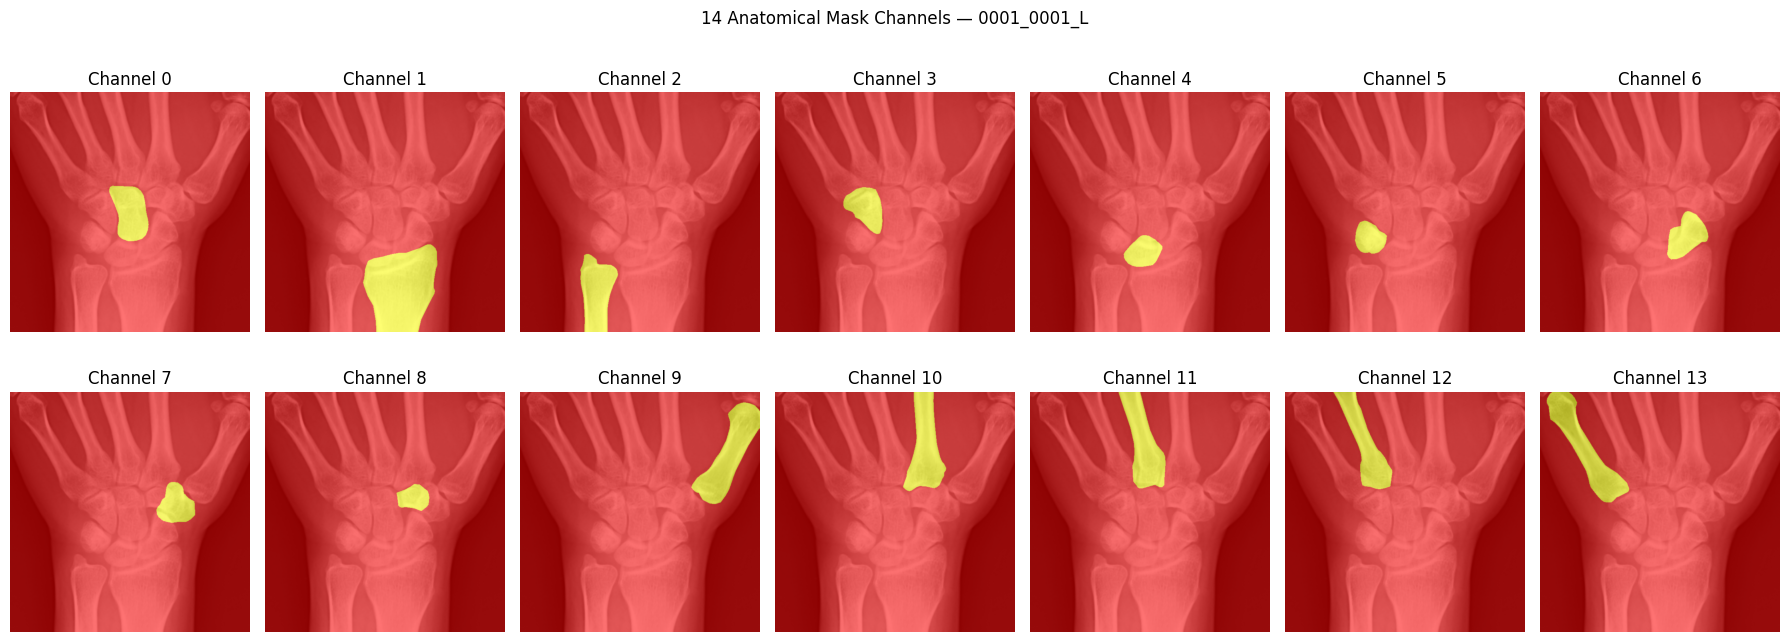

In [39]:

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

mask_dir = Path("/kaggle/working/RAM_Gaussian_All/masks")
image_dir = Path("/kaggle/working/RAM_Gaussian_All/images")

mask_path = sorted(mask_dir.glob("*.npy"))[0]
mask = np.load(mask_path)
image = np.load(image_dir / mask_path.name)

fig, axes = plt.subplots(2, 7, figsize=(18, 7))

for ch, ax in enumerate(axes.flat):
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.imshow(mask[ch], cmap="autumn", alpha=0.55)
    ax.set_title(f"Channel {ch}")
    ax.axis("off")

plt.suptitle(f"14 Anatomical Mask Channels — {mask_path.stem}")
plt.tight_layout()
plt.show()


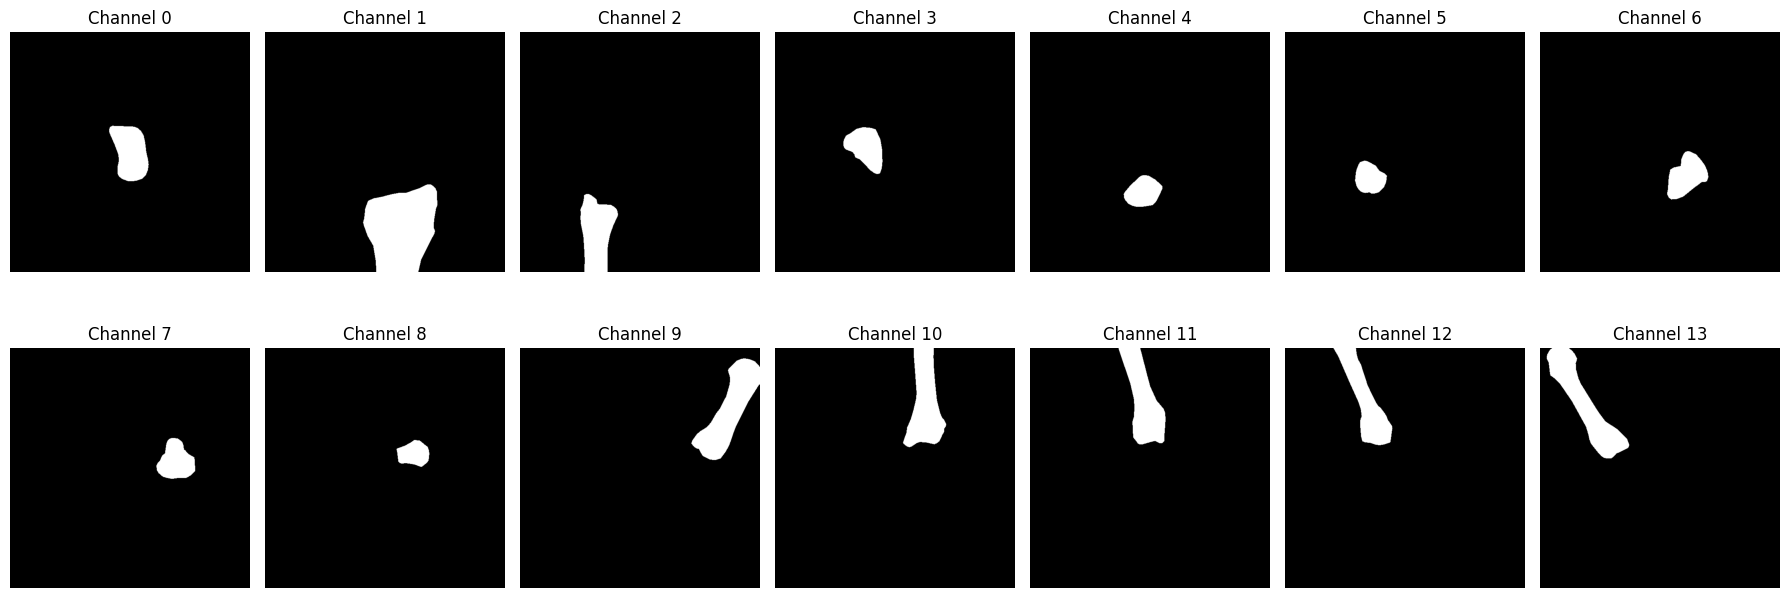

Mask shape: (14, 600, 600)
Pixels with multiple active channels: 8342
Maximum active channels at one pixel: 3
Channel 0: 9999 foreground pixels
Channel 1: 30476 foreground pixels
Channel 2: 12583 foreground pixels
Channel 3: 7461 foreground pixels
Channel 4: 5440 foreground pixels
Channel 5: 4813 foreground pixels
Channel 6: 7690 foreground pixels
Channel 7: 6806 foreground pixels
Channel 8: 3981 foreground pixels
Channel 9: 17741 foreground pixels
Channel 10: 15142 foreground pixels
Channel 11: 14733 foreground pixels
Channel 12: 13088 foreground pixels
Channel 13: 17364 foreground pixels


In [40]:

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

base = Path("/kaggle/working/RAM_Gaussian_All")
image_dir = base / "images"
mask_dir = base / "masks"

mask_path = sorted(mask_dir.glob("*.npy"))[0]
image = np.load(image_dir / mask_path.name)
mask = np.load(mask_path)

fig, axes = plt.subplots(2, 7, figsize=(18, 7))

for ch, ax in enumerate(axes.flat):
    ax.imshow(mask[ch], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Channel {ch}")
    ax.axis("off")

plt.tight_layout()
plt.show()

# Channel-wise foreground and overlap summary
overlap = np.sum(mask > 0, axis=0)

print("Mask shape:", mask.shape)
print("Pixels with multiple active channels:",
      np.count_nonzero(overlap > 1))
print("Maximum active channels at one pixel:", overlap.max())

for ch in range(mask.shape[0]):
    print(f"Channel {ch}: {np.count_nonzero(mask[ch])} foreground pixels")


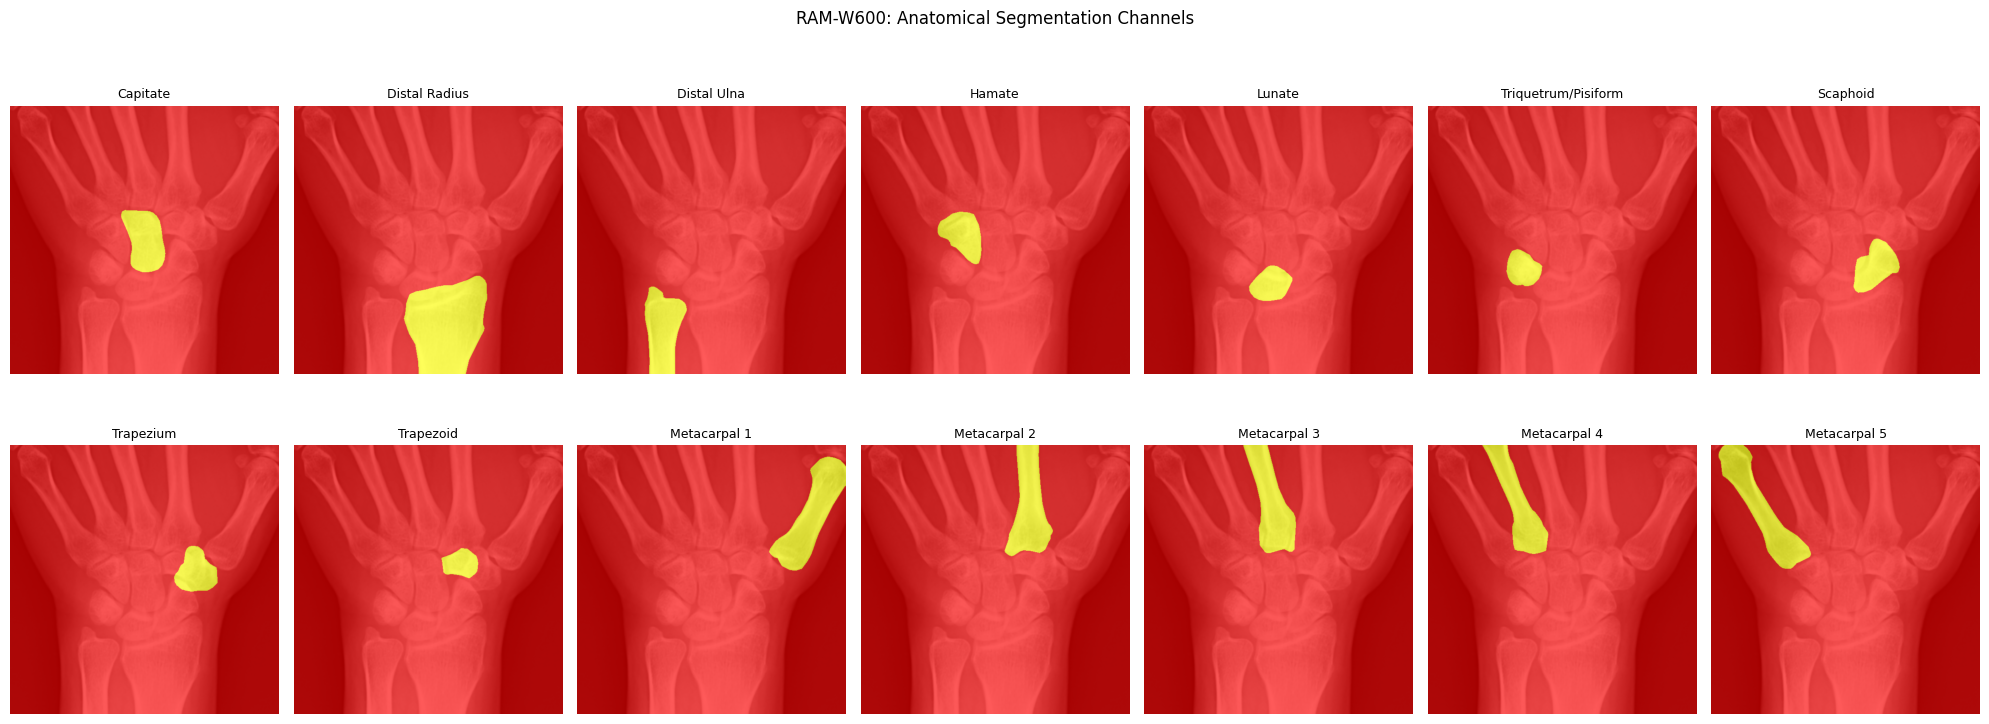

In [41]:

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

base = Path("/kaggle/working/RAM_Gaussian_All")
image_dir = base / "images"
mask_dir = base / "masks"

channel_names = [
    "Capitate", "Distal Radius", "Distal Ulna",
    "Hamate", "Lunate", "Triquetrum/Pisiform",
    "Scaphoid", "Trapezium", "Trapezoid",
    "Metacarpal 1", "Metacarpal 2", "Metacarpal 3",
    "Metacarpal 4", "Metacarpal 5"
]

mask_path = sorted(mask_dir.glob("*.npy"))[0]
image = np.load(image_dir / mask_path.name)
mask = np.load(mask_path)

fig, axes = plt.subplots(2, 7, figsize=(20, 8))

for ch, ax in enumerate(axes.flat):
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.imshow(mask[ch], cmap="autumn", alpha=0.65)
    ax.set_title(channel_names[ch], fontsize=9)
    ax.axis("off")

plt.suptitle("RAM-W600: Anatomical Segmentation Channels")
plt.tight_layout()
plt.show()


In [43]:
from pathlib import Path
import numpy as np
from collections import Counter

BASE = Path("/kaggle/working/RAM_Gaussian_All")
IMAGE_DIR = BASE / "images"
MASK_DIR = BASE / "masks"

image_files = {p.name: p for p in IMAGE_DIR.glob("*.npy")}
mask_files = {p.name: p for p in MASK_DIR.glob("*.npy")}

matched_names = sorted(set(image_files) & set(mask_files))

shape_counts = Counter()
mask_shape_counts = Counter()
invalid_reasons = Counter()
examples = []

for name in matched_names:
    image = np.load(image_files[name])
    mask = np.load(mask_files[name])

    shape_counts[str(image.shape)] += 1
    mask_shape_counts[str(mask.shape)] += 1

    reasons = []

    if image.shape != (600, 600):
        reasons.append("Image shape")

    if mask.shape != (14, 600, 600):
        reasons.append("Mask shape")

    if not np.isfinite(image).all():
        reasons.append("Image contains NaN/Inf")

    if not np.isin(mask, [0, 1]).all():
        reasons.append("Mask values not binary")

    if reasons:
        for reason in reasons:
            invalid_reasons[reason] += 1

        if len(examples) < 15:
            examples.append({
                "filename": name,
                "image_shape": image.shape,
                "image_min_max": (
                    float(np.nanmin(image)),
                    float(np.nanmax(image))
                ),
                "mask_shape": mask.shape,
                "mask_unique": np.unique(mask)[:10].tolist(),
                "reasons": reasons
            })

print("IMAGE SHAPES:")
for shape, count in shape_counts.items():
    print(shape, ":", count)

print("\nMASK SHAPES:")
for shape, count in mask_shape_counts.items():
    print(shape, ":", count)

print("\nINVALID REASONS:")
for reason, count in invalid_reasons.items():
    print(reason, ":", count)

print("\nINVALID EXAMPLES:")
for item in examples:
    print(item)

IMAGE SHAPES:
(600, 600) : 369
(720, 720) : 74
(650, 650) : 174
(640, 640) : 1

MASK SHAPES:
(14, 600, 600) : 369
(14, 720, 720) : 74
(14, 650, 650) : 174
(14, 640, 640) : 1

INVALID REASONS:
Image shape : 249
Mask shape : 249

INVALID EXAMPLES:
{'filename': '0144_0004_L.npy', 'image_shape': (720, 720), 'image_min_max': (0.0, 0.9999999403953552), 'mask_shape': (14, 720, 720), 'mask_unique': [0, 1], 'reasons': ['Image shape', 'Mask shape']}
{'filename': '0338_0001_L.npy', 'image_shape': (650, 650), 'image_min_max': (0.0, 0.9999999403953552), 'mask_shape': (14, 650, 650), 'mask_unique': [0, 1], 'reasons': ['Image shape', 'Mask shape']}
{'filename': '0338_0001_R.npy', 'image_shape': (650, 650), 'image_min_max': (0.0, 1.0), 'mask_shape': (14, 650, 650), 'mask_unique': [0, 1], 'reasons': ['Image shape', 'Mask shape']}
{'filename': '0338_0002_L.npy', 'image_shape': (650, 650), 'image_min_max': (-4.656612873077393e-10, 1.0), 'mask_shape': (14, 650, 650), 'mask_unique': [0, 1], 'reasons': ['Im

In [44]:
from pathlib import Path
import numpy as np
import cv2
import json

BASE = Path("/kaggle/working/RAM_Gaussian_All")
IMAGE_DIR = BASE / "images"
MASK_DIR = BASE / "masks"

OUT = Path("/kaggle/working/RAM_Resized_600")
OUT_IMAGES = OUT / "images"
OUT_MASKS = OUT / "masks"

OUT_IMAGES.mkdir(parents=True, exist_ok=True)
OUT_MASKS.mkdir(parents=True, exist_ok=True)

image_files = {p.name: p for p in IMAGE_DIR.glob("*.npy")}
mask_files = {p.name: p for p in MASK_DIR.glob("*.npy")}

matched = sorted(set(image_files) & set(mask_files))

success = 0
errors = []

for name in matched:
    try:
        image = np.load(image_files[name]).astype(np.float32)
        mask = np.load(mask_files[name])

        # Verify matching spatial dimensions
        if image.shape != mask.shape[1:]:
            raise ValueError(
                f"Image shape {image.shape} != mask shape {mask.shape}"
            )

        # Resize image using linear interpolation
        image_resized = cv2.resize(
            image, (600, 600),
            interpolation=cv2.INTER_LINEAR
        )

        # Resize each of the 14 binary mask channels separately
        mask_resized = np.stack([
            cv2.resize(
                channel.astype(np.uint8),
                (600, 600),
                interpolation=cv2.INTER_NEAREST
            )
            for channel in mask
        ], axis=0)

        # Save without collapsing the 14 channels
        np.save(OUT_IMAGES / name, image_resized.astype(np.float32))
        np.save(OUT_MASKS / name, mask_resized.astype(np.uint8))

        success += 1

    except Exception as e:
        errors.append({"filename": name, "error": str(e)})

print("Total matched pairs:", len(matched))
print("Successfully resized:", success)
print("Errors:", len(errors))
print("Output:", OUT)

if errors:
    print("First errors:", errors[:5])

# Final dimension check
if success:
    sample_name = sorted(
        p.name for p in OUT_IMAGES.glob("*.npy")
    )[0]

    check_image = np.load(OUT_IMAGES / sample_name)
    check_mask = np.load(OUT_MASKS / sample_name)

    print("Sample image shape:", check_image.shape)
    print("Sample mask shape:", check_mask.shape)
    print("Mask values:", np.unique(check_mask))

Total matched pairs: 618
Successfully resized: 618
Errors: 0
Output: /kaggle/working/RAM_Resized_600
Sample image shape: (600, 600)
Sample mask shape: (14, 600, 600)
Mask values: [0 1]


In [45]:
from pathlib import Path
import random
import json

BASE = Path("/kaggle/working/RAM_Resized_600")
IMAGE_DIR = BASE / "images"
MASK_DIR = BASE / "masks"

OUT = Path("/kaggle/working/RAM_Final_Split")
OUT.mkdir(parents=True, exist_ok=True)

# Match image-mask filenames
images = {p.name for p in IMAGE_DIR.glob("*.npy")}
masks = {p.name for p in MASK_DIR.glob("*.npy")}
pairs = sorted(images & masks)

print("Total matched pairs:", len(pairs))
print("Images without masks:", len(images - masks))
print("Masks without images:", len(masks - images))

# Reproducible shuffle
random.seed(42)
random.shuffle(pairs)

# 70% train, 15% validation, 15% test
n = len(pairs)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_files = pairs[:train_end]
val_files = pairs[train_end:val_end]
test_files = pairs[val_end:]

# Save filenames
splits = {
    "train_files.json": train_files,
    "val_files.json": val_files,
    "test_files.json": test_files
}

for filename, file_list in splits.items():
    with open(OUT / filename, "w") as f:
        json.dump(file_list, f, indent=2)

print("\n--- DATASET SPLIT RESULTS ---")
print(f"Training:   {len(train_files)} ({len(train_files)/n*100:.2f}%)")
print(f"Validation: {len(val_files)} ({len(val_files)/n*100:.2f}%)")
print(f"Testing:    {len(test_files)} ({len(test_files)/n*100:.2f}%)")
print("Output directory:", OUT)

Total matched pairs: 618
Images without masks: 0
Masks without images: 0

--- DATASET SPLIT RESULTS ---
Training:   432 (69.90%)
Validation: 93 (15.05%)
Testing:    93 (15.05%)
Output directory: /kaggle/working/RAM_Final_Split


In [49]:
import torch
import torch.nn.functional as F
import types

def fixed_forward(self, x):
    e1 = self.enc1(x)
    e2 = self.enc2(self.pool(e1))
    e3 = self.enc3(self.pool(e2))
    e4 = self.enc4(self.pool(e3))

    b = self.bottleneck(self.pool(e4))

    d4 = self.up4(b)
    d4 = F.interpolate(
        d4, size=e4.shape[2:],
        mode="bilinear", align_corners=False
    )
    d4 = self.dec4(torch.cat([d4, e4], dim=1))

    d3 = self.up3(d4)
    d3 = F.interpolate(
        d3, size=e3.shape[2:],
        mode="bilinear", align_corners=False
    )
    d3 = self.dec3(torch.cat([d3, e3], dim=1))

    d2 = self.up2(d3)
    d2 = F.interpolate(
        d2, size=e2.shape[2:],
        mode="bilinear", align_corners=False
    )
    d2 = self.dec2(torch.cat([d2, e2], dim=1))

    d1 = self.up1(d2)
    d1 = F.interpolate(
        d1, size=e1.shape[2:],
        mode="bilinear", align_corners=False
    )
    d1 = self.dec1(torch.cat([d1, e1], dim=1))

    return self.out_conv(d1)


# Patch the existing model instance directly
model.forward = types.MethodType(fixed_forward, model)
model.eval()

images, masks = next(iter(train_loader))
images = images.to(device)
masks = masks.to(device)

with torch.no_grad():
    logits = model(images)

print("Input :", tuple(images.shape))
print("Target:", tuple(masks.shape))
print("Output:", tuple(logits.shape))

assert logits.shape == masks.shape
print("SUCCESS: 14-channel output matches target masks.")

Input : (2, 1, 600, 600)
Target: (2, 14, 600, 600)
Output: (2, 14, 600, 600)
SUCCESS: 14-channel output matches target masks.


In [56]:
import torch
import torch.nn as nn
import numpy as np
from pathlib import Path

# Training configuration
EPOCHS = 10
LEARNING_RATE = 1e-3

SAVE_DIR = Path("/kaggle/working/RAM_Model")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

best_val_dice = 0.0
history = []

def calculate_dice(logits, targets, threshold=0.5, eps=1e-7):
    predictions = (torch.sigmoid(logits) >= threshold).float()

    intersection = (predictions * targets).sum(dim=(0, 2, 3))
    denominator = predictions.sum(dim=(0, 2, 3)) + targets.sum(dim=(0, 2, 3))

    # Ignore channels that have no foreground in both prediction and target
    valid = denominator > 0

    if valid.any():
        dice = (
            (2 * intersection[valid] + eps) /
            (denominator[valid] + eps)
        )
        return dice.mean().item()

    return 1.0


for epoch in range(EPOCHS):
    # Training
    model.train()
    train_losses = []

    for images, masks in train_loader:
        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        logits = model(images)
        loss = criterion(logits, masks)

        loss.backward()
        optimizer.step()

        train_losses.append(loss.item())

    # Validation
    model.eval()
    val_losses = []
    val_dices = []

    with torch.no_grad():
        for images, masks in val_loader:
            images = images.to(device)
            masks = masks.to(device)

            logits = model(images)
            loss = criterion(logits, masks)

            val_losses.append(loss.item())
            val_dices.append(calculate_dice(logits, masks))

    train_loss = float(np.mean(train_losses))
    val_loss = float(np.mean(val_losses))
    val_dice = float(np.mean(val_dices))

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_dice": val_dice
    })

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Dice: {val_dice:.4f}"
    )

    if val_dice > best_val_dice:
        best_val_dice = val_dice

        torch.save(
            model.state_dict(),
            SAVE_DIR / "best_unet.pth"
        )

        print("  Best model saved.")

print("\nTraining completed.")
print("Best validation Dice:", round(best_val_dice, 4))
print("Model path:", SAVE_DIR / "best_unet.pth")

KeyboardInterrupt: 

In [54]:
import torch
import numpy as np
import pandas as pd
from pathlib import Path

# Load best model saved during training
SAVE_DIR = Path("/kaggle/working/RAM_Model")
MODEL_PATH = SAVE_DIR / "best_unet.pth"

assert MODEL_PATH.exists(), (
    "best_unet.pth not found. Run the training cell first."
)

model.load_state_dict(
    torch.load(MODEL_PATH, map_location=device)
)
model.to(device)
model.eval()

# Accumulate metrics for each of the 14 channels
TP = torch.zeros(14, dtype=torch.float64)
FP = torch.zeros(14, dtype=torch.float64)
FN = torch.zeros(14, dtype=torch.float64)
TN = torch.zeros(14, dtype=torch.float64)

with torch.no_grad():
    for images, masks in test_loader:
        images = images.to(device)
        masks = masks.to(device)

        logits = model(images)
        predictions = (torch.sigmoid(logits) >= 0.5)
        targets = masks >= 0.5

        TP += (predictions & targets).sum(dim=(0, 2, 3)).cpu()
        FP += (predictions & ~targets).sum(dim=(0, 2, 3)).cpu()
        FN += (~predictions & targets).sum(dim=(0, 2, 3)).cpu()
        TN += (~predictions & ~targets).sum(dim=(0, 2, 3)).cpu()

eps = 1e-8

dice = (2 * TP + eps) / (2 * TP + FP + FN + eps)
iou = (TP + eps) / (TP + FP + FN + eps)
precision = (TP + eps) / (TP + FP + eps)
recall = (TP + eps) / (TP + FN + eps)

# Per-channel results
channel_names = [
    "Capitate", "Distal Radius", "Distal Ulna", "Hamate",
    "Lunate", "Triquetrum/Pisiform", "Scaphoid", "Trapezium",
    "Trapezoid", "Metacarpal 1", "Metacarpal 2",
    "Metacarpal 3", "Metacarpal 4", "Metacarpal 5"
]

results = pd.DataFrame({
    "Channel": channel_names,
    "Dice": dice.numpy(),
    "IoU": iou.numpy(),
    "Precision": precision.numpy(),
    "Recall": recall.numpy()
})

print("TEST RESULTS — PER CHANNEL")
display(results.round(4))

print("\nMEAN TEST METRICS")
print(f"Dice      : {dice.mean().item():.4f}")
print(f"IoU       : {iou.mean().item():.4f}")
print(f"Precision : {precision.mean().item():.4f}")
print(f"Recall    : {recall.mean().item():.4f}")

results.to_csv(
    SAVE_DIR / "test_channel_metrics.csv",
    index=False
)

print("\nSaved:", SAVE_DIR / "test_channel_metrics.csv")

TEST RESULTS — PER CHANNEL


,Channel,Dice,IoU,Precision,Recall
0,Capitate,0.9509,0.9063,0.9327,0.9698
1,Distal Radius,0.9799,0.9605,0.9868,0.9730
2,Distal Ulna,0.9766,0.9542,0.9816,0.9716
3,Hamate,0.9430,0.8922,0.9721,0.9156
4,Lunate,0.9325,0.8736,0.9268,0.9383
5,Triquetrum/Pisiform,0.9501,0.9049,0.9548,0.9454
6,Scaphoid,0.9560,0.9158,0.9648,0.9475
7,Trapezium,0.9449,0.8955,0.9460,0.9438
8,Trapezoid,0.9120,0.8382,0.9059,0.9181
9,Metacarpal 1,0.9769,0.9549,0.9846,0.9694



MEAN TEST METRICS
Dice      : 0.9568
IoU       : 0.9179
Precision : 0.9585
Recall    : 0.9554

Saved: /kaggle/working/RAM_Model/test_channel_metrics.csv


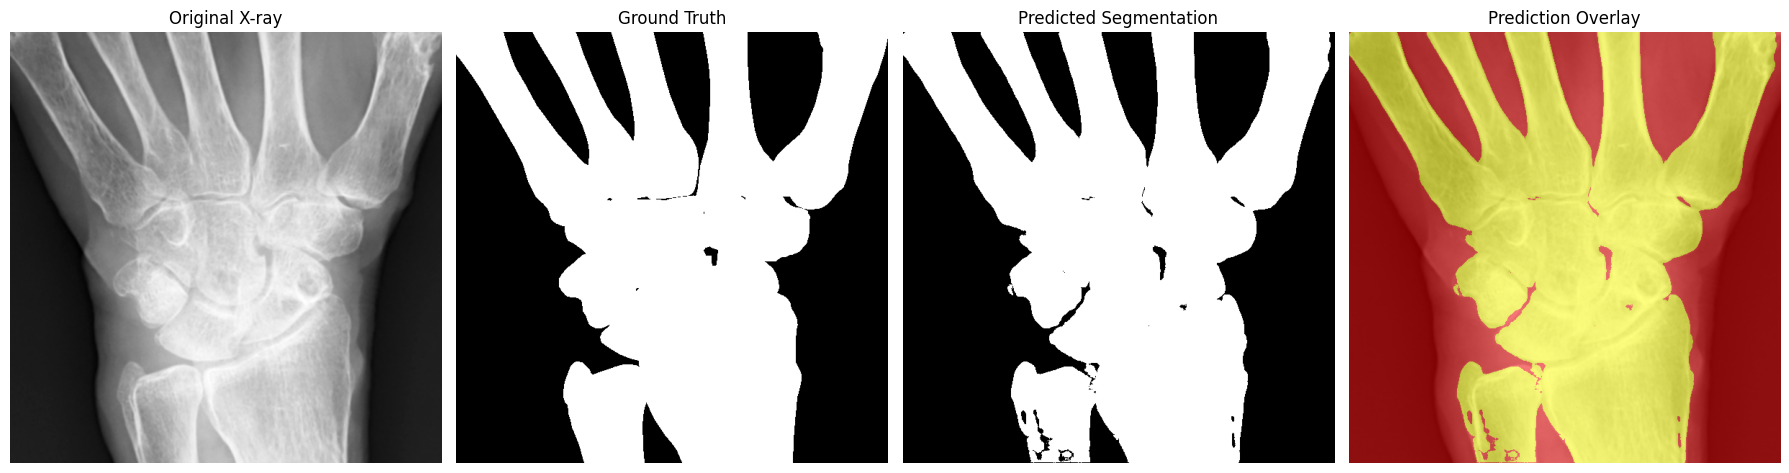

In [57]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

BASE = Path("/kaggle/working/RAM_Resized_600")
SAVE_DIR = Path("/kaggle/working/RAM_Model")

# Load best saved model
model.load_state_dict(
    torch.load(SAVE_DIR / "best_unet.pth", map_location=device)
)
model.to(device)
model.eval()

# Select one test image
sample_name = test_files[0]

image = np.load(BASE / "images" / sample_name).astype(np.float32)
mask = np.load(BASE / "masks" / sample_name).astype(np.float32)

# Predict segmentation
input_tensor = torch.from_numpy(image).unsqueeze(0).unsqueeze(0).to(device)

with torch.no_grad():
    logits = model(input_tensor)
    prediction = (torch.sigmoid(logits)[0] >= 0.5).cpu().numpy()

# Combine channels only for visualization; original masks remain unchanged
ground_truth = np.any(mask > 0.5, axis=0)
predicted_mask = np.any(prediction, axis=0)

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("Original X-ray")

axes[1].imshow(ground_truth, cmap="gray")
axes[1].set_title("Ground Truth")

axes[2].imshow(predicted_mask, cmap="gray")
axes[2].set_title("Predicted Segmentation")

axes[3].imshow(image, cmap="gray")
axes[3].imshow(predicted_mask, cmap="autumn", alpha=0.5)
axes[3].set_title("Prediction Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [62]:
import json
import numpy as np
import torch
import torch.nn as nn
from pathlib import Path
from PIL import Image
from torchvision import models
from torchvision.models import ResNet50_Weights, ViT_B_16_Weights

# Paths
BASE = Path("/kaggle/working/RAM_Resized_600")
SPLIT_DIR = Path("/kaggle/working/RAM_Final_Split")
OUT_DIR = Path("/kaggle/working/RAM_Features")
OUT_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Load dataset splits
with open(SPLIT_DIR / "train_files.json") as f:
    train_files = json.load(f)

with open(SPLIT_DIR / "val_files.json") as f:
    val_files = json.load(f)

with open(SPLIT_DIR / "test_files.json") as f:
    test_files = json.load(f)

# Pretrained ResNet-50
resnet = models.resnet50(weights=ResNet50_Weights.DEFAULT)
resnet.fc = nn.Identity()
resnet = resnet.to(device).eval()

# Pretrained Vision Transformer
vit = models.vit_b_16(weights=ViT_B_16_Weights.DEFAULT)
vit.heads = nn.Identity()
vit = vit.to(device).eval()

# ImageNet normalization
mean = torch.tensor(
    [0.485, 0.456, 0.406], device=device
).view(1, 3, 1, 1)

std = torch.tensor(
    [0.229, 0.224, 0.225], device=device
).view(1, 3, 1, 1)


def extract_features(files, split_name):
    vit_list = []
    resnet_list = []
    filenames = []

    for i, name in enumerate(files):
        # Load preprocessed X-ray
        img = np.load(BASE / "images" / name).astype(np.float32)
        img = np.clip(img, 0, 1)

        # Convert grayscale to RGB and resize
        rgb = np.repeat(img[:, :, None], 3, axis=2)
        rgb = Image.fromarray(
            (rgb * 255).astype(np.uint8)
        ).resize((224, 224), Image.Resampling.BILINEAR)

        rgb = np.asarray(rgb).astype(np.float32) / 255.0

        x = torch.from_numpy(rgb).permute(2, 0, 1).unsqueeze(0)
        x = x.to(device)
        x = (x - mean) / std

        with torch.no_grad():
            resnet_feat = resnet(x)
            vit_feat = vit(x)

        resnet_list.append(resnet_feat.squeeze(0).cpu().numpy())
        vit_list.append(vit_feat.squeeze(0).cpu().numpy())
        filenames.append(name)

        if (i + 1) % 25 == 0 or i + 1 == len(files):
            print(f"{split_name}: {i+1}/{len(files)} images")

    vit_array = np.asarray(vit_list, dtype=np.float32)
    resnet_array = np.asarray(resnet_list, dtype=np.float32)
    fused_array = np.concatenate([vit_array, resnet_array], axis=1)

    np.savez_compressed(
        OUT_DIR / f"{split_name}_features.npz",
        filenames=np.asarray(filenames),
        vit_features=vit_array,
        resnet_features=resnet_array,
        fused_features=fused_array
    )

    print(
        f"{split_name} complete | "
        f"ViT: {vit_array.shape} | "
        f"ResNet-50: {resnet_array.shape} | "
        f"Combined: {fused_array.shape}"
    )


# Extract features for all splits
extract_features(train_files, "train")
extract_features(val_files, "validation")
extract_features(test_files, "test")

print("\nStep 6 completed.")
print("Feature files saved in:", OUT_DIR)

Device: cpu
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 119MB/s] 


Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:02<00:00, 130MB/s]  


train: 25/432 images
train: 50/432 images
train: 75/432 images
train: 100/432 images
train: 125/432 images
train: 150/432 images
train: 175/432 images
train: 200/432 images
train: 225/432 images
train: 250/432 images
train: 275/432 images
train: 300/432 images
train: 325/432 images
train: 350/432 images
train: 375/432 images
train: 400/432 images
train: 425/432 images
train: 432/432 images
train complete | ViT: (432, 768) | ResNet-50: (432, 2048) | Combined: (432, 2816)
validation: 25/93 images
validation: 50/93 images
validation: 75/93 images
validation: 93/93 images
validation complete | ViT: (93, 768) | ResNet-50: (93, 2048) | Combined: (93, 2816)
test: 25/93 images
test: 50/93 images
test: 75/93 images
test: 93/93 images
test complete | ViT: (93, 768) | ResNet-50: (93, 2048) | Combined: (93, 2816)

Step 6 completed.
Feature files saved in: /kaggle/working/RAM_Features


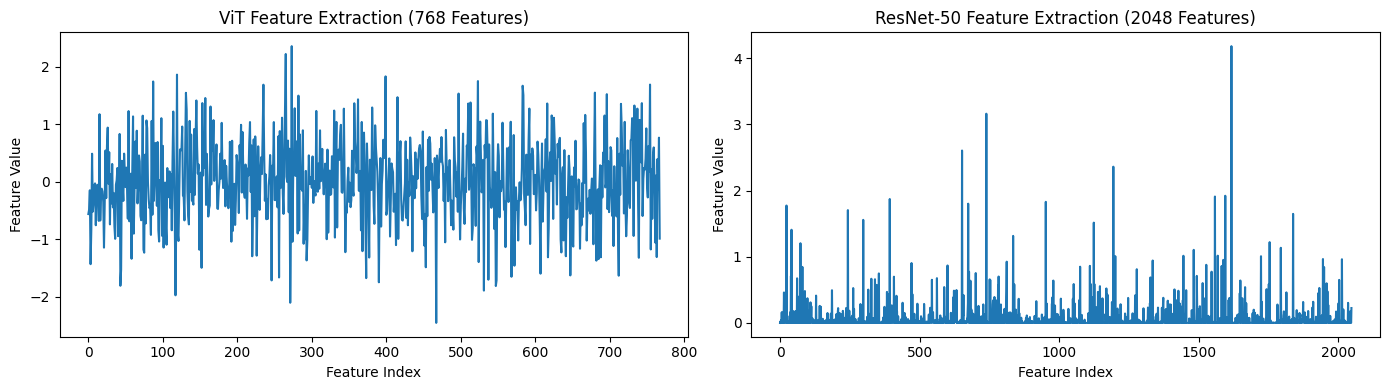

In [63]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

file_path = Path("/kaggle/working/RAM_Features/test_features.npz")
data = np.load(file_path)

vit = data["vit_features"][0]
resnet = data["resnet_features"][0]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(vit)
axes[0].set_title("ViT Feature Extraction (768 Features)")
axes[0].set_xlabel("Feature Index")
axes[0].set_ylabel("Feature Value")

axes[1].plot(resnet)
axes[1].set_title("ResNet-50 Feature Extraction (2048 Features)")
axes[1].set_xlabel("Feature Index")
axes[1].set_ylabel("Feature Value")

plt.tight_layout()
plt.show()

In [64]:
import os
import json
from pathlib import Path

base_path = Path("/kaggle/working/RAM_Final_Split")

print("=== DATASET LABEL CHECK ===")

for split in ["train", "val", "test"]:
    file_path = base_path / f"{split}_files.json"

    if file_path.exists():
        with open(file_path, "r") as f:
            data = json.load(f)

        print(f"{split}: {len(data)} entries")
        print("Sample:", data[:3] if isinstance(data, list) else list(data)[:3])
    else:
        print(f"{split}: File not found")

print("\n=== FEATURE FILE CHECK ===")

feature_path = Path("/kaggle/working/RAM_Features")

for split in ["train", "validation", "test"]:
    file_path = feature_path / f"{split}_features.npz"

    if file_path.exists():
        import numpy as np
        data = np.load(file_path)
        print(f"\n{split}:")
        print("ViT:", data["vit_features"].shape)
        print("ResNet:", data["resnet_features"].shape)
    else:
        print(f"{split}: Feature file not found")

=== DATASET LABEL CHECK ===
train: 432 entries
Sample: ['0067_0001_L.npy', '0300_0002_R.npy', '0055_0001_L.npy']
val: 93 entries
Sample: ['EXT_0045_0001_L.npy', '0047_0001_L.npy', '0345_0001_L.npy']
test: 93 entries
Sample: ['0139_0005_L.npy', 'EXT_0122_0001_R.npy', '0143_0011_L.npy']

=== FEATURE FILE CHECK ===

train:
ViT: (432, 768)
ResNet: (432, 2048)

validation:
ViT: (93, 768)
ResNet: (93, 2048)

test:
ViT: (93, 768)
ResNet: (93, 2048)


In [65]:
from pathlib import Path

base = Path("/kaggle/working/RAM-W600")

print("=== SEARCHING FOR CLASS LABEL FILES ===")

extensions = ["*.csv", "*.json", "*.xlsx", "*.txt"]

for ext in extensions:
    files = list(base.rglob(ext))
    print(f"\n{ext} files: {len(files)}")

    for f in files[:15]:
        print(f)

=== SEARCHING FOR CLASS LABEL FILES ===

*.csv files: 0

*.json files: 4
/kaggle/working/RAM-W600/SvdHBEScoreClassification/JointBE_SvdH_GT.json
/kaggle/working/RAM-W600/SvdHBEScoreClassification/JointBE_SvdH_GT_Ori.json
/kaggle/working/RAM-W600/JointLocationDetection/Joints.coco.json
/kaggle/working/RAM-W600/.cache/huggingface/trees/98af1c15ce8b5ff907a180c5d6b883d29a76045f.json

*.xlsx files: 1
/kaggle/working/RAM-W600/Metadata.xlsx

*.txt files: 0


In [66]:
import pandas as pd
import json
from pathlib import Path

base = Path("/kaggle/working/RAM-W600")

# 1. Inspect Excel metadata
excel_path = base / "Metadata.xlsx"

if excel_path.exists():
    xls = pd.ExcelFile(excel_path)
    print("Excel sheets:", xls.sheet_names)

    for sheet in xls.sheet_names:
        df = pd.read_excel(excel_path, sheet_name=sheet)
        print(f"\n--- Sheet: {sheet} ---")
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        display(df.head(10))
else:
    print("Metadata.xlsx not found")

# 2. Inspect classification JSON files
json_files = [
    base / "SvdHBEScoreClassification/JointBE_SvdH_GT.json",
    base / "SvdHBEScoreClassification/JointBE_SvdH_GT_ori.json",
    base / "JointLocationDetection/Joints.json"
]

for path in json_files:
    if path.exists():
        print(f"\n--- {path.name} ---")
        with open(path, "r") as f:
            obj = json.load(f)

        print("Data type:", type(obj).__name__)

        if isinstance(obj, dict):
            print("Keys:", list(obj.keys())[:30])
            print(json.dumps(obj, indent=2)[:2500])
        elif isinstance(obj, list):
            print("Number of entries:", len(obj))
            print(json.dumps(obj[:3], indent=2)[:2500])

Excel sheets: ['Filtered']

--- Sheet: Filtered ---
Shape: (611, 26)
Columns: ['Mapped Image Stem', 'StudyID', 'PatientID', 'IsRA', 'PatientSex', 'PatientAge', 'InstitutionName', 'StudyDate (Days)', 'ImagerPixelSpacing', '[Rows, Columns]', 'L', 'R', 'SvdH_L', 'SvdH_R', '1st MC_L', 'Trapz_L', 'Sc_L', 'Lu_L', 'DR_L', 'DU_L', '1st MC_R', 'Trapz_R', 'Sc_R', 'Lu_R', 'DR_R', 'DU_R']


,Mapped Image Stem,StudyID,PatientID,IsRA,PatientSex,PatientAge,InstitutionName,StudyDate (Days),ImagerPixelSpacing,"[Rows, Columns]",...,Sc_L,Lu_L,DR_L,DU_L,1st MC_R,Trapz_R,Sc_R,Lu_R,DR_R,DU_R
0,0001_0001,1,1,1,F,59.5,HMCRD,0,"[0.15, 0.15]","[1670, 2010]",...,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0
1,0002_0001,1,2,1,F,71.5,HMCRD,0,"[0.15, 0.15]","[1670, 2010]",...,2.0,0.0,0.0,2.0,0.0,1.0,2.0,1.0,0.0,0.0
2,0003_0001,1,3,1,F,64.5,HMCRD,0,"[0.15, 0.15]","[1670, 2010]",...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0005_0001,1,5,1,F,51.5,HMCRD,0,"[0.15, 0.15]","[1670, 2010]",...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0006_0001,1,6,1,F,50.5,HMCRD,0,"[0.15, 0.15]","[1670, 2010]",...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0007_0001,1,7,1,F,64.5,HMCRD,0,"[0.15, 0.15]","[1670, 2010]",...,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,0008_0001,1,8,1,F,57.5,HMCRD,0,"[0.15, 0.15]","[1670, 2010]",...,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
7,0009_0001,1,9,1,F,78.5,HMCRD,0,"[0.15, 0.15]","[1670, 2010]",...,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0
8,0010_0001,1,10,1,F,76.5,HMCRD,0,"[0.15, 0.15]","[1670, 2010]",...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,2.0
9,0011_0001,1,11,1,F,56.5,HMCRD,0,"[0.15, 0.15]","[1670, 2010]",...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



--- JointBE_SvdH_GT.json ---
Data type: list
Number of entries: 800
[
  {
    "identifier": "0001_0001_L",
    "patient_id": "0001",
    "study_id": "0001",
    "hand": "L",
    "joints": {
      "Metacarpal1st": 0,
      "Trapzium": 0,
      "Scaphoid": 0,
      "Lunate": 0,
      "DistalRadius": 0,
      "DistalUlna": 0
    }
  },
  {
    "identifier": "0001_0001_R",
    "patient_id": "0001",
    "study_id": "0001",
    "hand": "R",
    "joints": {
      "Metacarpal1st": 0,
      "Trapzium": 0,
      "Scaphoid": 2,
      "Lunate": 0,
      "DistalRadius": 0,
      "DistalUlna": 0
    }
  },
  {
    "identifier": "0002_0001_L",
    "patient_id": "0002",
    "study_id": "0001",
    "hand": "L",
    "joints": {
      "Metacarpal1st": 0,
      "Trapzium": 2,
      "Scaphoid": 2,
      "Lunate": 0,
      "DistalRadius": 0,
      "DistalUlna": 2
    }
  }
]


Total metadata rows: 611

IsRA unique values:
IsRA
0    185
1    426
Name: count, dtype: int64

IsRA value meanings — verify from dataset documentation:
Unique values: [0, 1]


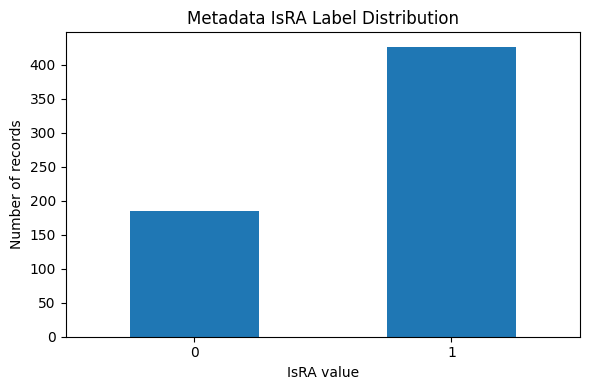


Feature filename example: ['0067_0001_L.npy' '0300_0002_R.npy' '0055_0001_L.npy'
 'EXT_0090_0001_R.npy' '0369_0001_R.npy']
Metadata image-stem example: ['0001_0001', '0002_0001', '0003_0001', '0005_0001', '0006_0001']


In [67]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

metadata_path = Path("/kaggle/working/RAM-W600/Metadata.xlsx")
df = pd.read_excel(metadata_path, sheet_name="Filtered")

print("Total metadata rows:", len(df))
print("\nIsRA unique values:")
print(df["IsRA"].value_counts(dropna=False).sort_index())

print("\nIsRA value meanings — verify from dataset documentation:")
print("Unique values:", sorted(df["IsRA"].dropna().unique().tolist()))

# Plot class distribution
counts = df["IsRA"].value_counts(dropna=False).sort_index()

plt.figure(figsize=(6, 4))
counts.plot(kind="bar")
plt.title("Metadata IsRA Label Distribution")
plt.xlabel("IsRA value")
plt.ylabel("Number of records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Check image-stem overlap with extracted feature filenames
import numpy as np

features = np.load(
    "/kaggle/working/RAM_Features/train_features.npz",
    allow_pickle=True
)

print("\nFeature filename example:", features["filenames"][:5])
print("Metadata image-stem example:", df["Mapped Image Stem"].head().tolist())

In [68]:
import numpy as np
import pandas as pd
from pathlib import Path

# Load metadata
df = pd.read_excel(
    "/kaggle/working/RAM-W600/Metadata.xlsx",
    sheet_name="Filtered"
)

# Load all feature splits
feature_dir = Path("/kaggle/working/RAM_Features")
splits = ["train", "validation", "test"]

feature_dfs = []

for split in splits:
    path = feature_dir / f"{split}_features.npz"
    data = np.load(path, allow_pickle=True)

    part = pd.DataFrame({
        "filename": data["filenames"].astype(str),
        "split": split,
        "feature_index": np.arange(len(data["filenames"]))
    })
    feature_dfs.append(part)

features_df = pd.concat(feature_dfs, ignore_index=True)

# Normalize filename stems for matching
def clean_stem(value):
    return Path(str(value)).stem.replace(".png", "").strip()

features_df["stem"] = features_df["filename"].apply(clean_stem)
df["stem"] = df["Mapped Image Stem"].astype(str).str.strip()

# Check exact matching
matched = features_df.merge(
    df[["stem", "IsRA", "PatientID"]],
    on="stem",
    how="inner"
)

print("Feature images:", len(features_df))
print("Metadata rows:", len(df))
print("Matched feature images:", len(matched))
print("Unmatched feature images:", len(features_df) - len(matched))
print("\nMatched labels:")
print(matched["IsRA"].value_counts(dropna=False))

display(matched.head(10))

Feature images: 618
Metadata rows: 611
Matched feature images: 0
Unmatched feature images: 618

Matched labels:
Series([], Name: count, dtype: int64)


,filename,split,feature_index,stem,IsRA,PatientID


In [70]:
import numpy as np
import pandas as pd
from pathlib import Path

# Metadata
df = pd.read_excel(
    "/kaggle/working/RAM-W600/Metadata.xlsx",
    sheet_name="Filtered"
)

# Feature filenames
data = np.load(
    "/kaggle/working/RAM_Features/train_features.npz",
    allow_pickle=True
)

print("=== METADATA FILENAMES ===")
print(df["Mapped Image Stem"].head(10).tolist())

print("\n=== FEATURE FILENAMES ===")
print(data["filenames"][:10].tolist())

print("\n=== METADATA STEM EXAMPLES ===")
print(df["Mapped Image Stem"].astype(str).str.strip().head(10).tolist())

print("\n=== FEATURE STEM EXAMPLES ===")
print([
    Path(str(x)).stem
    for x in data["filenames"][:10]
])

=== METADATA FILENAMES ===
['0001_0001', '0002_0001', '0003_0001', '0005_0001', '0006_0001', '0007_0001', '0008_0001', '0009_0001', '0010_0001', '0011_0001']

=== FEATURE FILENAMES ===
['0067_0001_L.npy', '0300_0002_R.npy', '0055_0001_L.npy', 'EXT_0090_0001_R.npy', '0369_0001_R.npy', 'EXT_0127_0001_L.npy', '0129_0005_L.npy', '0149_0006_L.npy', '0072_0001_L.npy', 'EXT_0095_0001_R.npy']

=== METADATA STEM EXAMPLES ===
['0001_0001', '0002_0001', '0003_0001', '0005_0001', '0006_0001', '0007_0001', '0008_0001', '0009_0001', '0010_0001', '0011_0001']

=== FEATURE STEM EXAMPLES ===
['0067_0001_L', '0300_0002_R', '0055_0001_L', 'EXT_0090_0001_R', '0369_0001_R', 'EXT_0127_0001_L', '0129_0005_L', '0149_0006_L', '0072_0001_L', 'EXT_0095_0001_R']


In [71]:
import numpy as np
import pandas as pd
from pathlib import Path

# 1. Load metadata
df = pd.read_excel(
    "/kaggle/working/RAM-W600/Metadata.xlsx",
    sheet_name="Filtered"
)

df["stem"] = df["Mapped Image Stem"].astype(str).str.strip()

# 2. Load all feature splits
feature_dir = Path("/kaggle/working/RAM_Features")
records = []

for split in ["train", "validation", "test"]:
    data = np.load(
        feature_dir / f"{split}_features.npz",
        allow_pickle=True
    )

    for i, filename in enumerate(data["filenames"]):
        name = Path(str(filename)).stem

        # Remove left/right suffix to obtain image stem
        if name.endswith("_L") or name.endswith("_R"):
            name = name[:-2]

        records.append({
            "stem": name,
            "original_filename": str(filename),
            "split": split,
            "vit": data["vit_features"][i],
            "resnet": data["resnet_features"][i]
        })

feature_df = pd.DataFrame(records)

# 3. Match with metadata
matched = feature_df.merge(
    df[["stem", "IsRA", "PatientID"]],
    on="stem",
    how="inner"
)

print("Feature entries:", len(feature_df))
print("Metadata rows:", len(df))
print("Matched entries:", len(matched))
print("Unmatched entries:", len(feature_df) - len(matched))

print("\nMatched labels:")
print(matched["IsRA"].value_counts())

print("\nMatched samples:")
display(
    matched[["original_filename", "stem", "IsRA", "PatientID"]].head(10)
)

Feature entries: 618
Metadata rows: 611
Matched entries: 618
Unmatched entries: 0

Matched labels:
IsRA
1    370
0    248
Name: count, dtype: int64

Matched samples:


,original_filename,stem,IsRA,PatientID
0,0067_0001_L.npy,0067_0001,1,67
1,0300_0002_R.npy,0300_0002,1,300
2,0055_0001_L.npy,0055_0001,1,55
3,EXT_0090_0001_R.npy,EXT_0090_0001,0,EXT_0090
4,0369_0001_R.npy,0369_0001,0,369
5,EXT_0127_0001_L.npy,EXT_0127_0001,0,EXT_0127
6,0129_0005_L.npy,0129_0005,1,129
7,0149_0006_L.npy,0149_0006,1,149
8,0072_0001_L.npy,0072_0001,1,72
9,EXT_0095_0001_R.npy,EXT_0095_0001,0,EXT_0095
